# The Catalytic `EC'` Mechanism

## 1. Goal

Model a pseudo-first-order catalytic `EC'` mechanism ($\text{Ox} + e^- \rightleftharpoons \text{Red}$, $\text{Red} \xrightarrow{k_{\text{cat}}} \text{Ox}$) using `CatalyticReaction` and verify the transition from a peaked CV to a sigmoidal catalytic plateau $I_{\text{cat}} = -n F A c^* \sqrt{D k_{\text{cat}}}$.

## 2. Physical Setup

We couple a fast reversible-limit `ButlerVolmer` step ($k^0 = 10^{-2}\text{ m/s}$) with `CatalyticReaction(red, ox, k=k_cat)` across $k_{\text{cat}} \in \{0, 0.5, 2.0, 10.0\}\text{ s}^{-1}$.

In [1]:
# !pip install -q softpotato

import matplotlib.pyplot as plt
import numpy as np

from softpotato.constants import FARADAY
from softpotato.geometry import PlanarGeometry
from softpotato.reactions import (
    ButlerVolmer,
    CatalyticReaction,
    ElectrochemicalStep,
    Mechanism,
    Species,
)
from softpotato.techniques import CyclicVoltammetry, simulate

E0 = 0.0
D = 1.0e-9
c_bulk = 1.0
area = 7.07e-6
v = 0.1

ox = Species("Ox", diffusivity=D, bulk_concentration=c_bulk, standard_potential=E0, n_electrons=1)
red = Species("Red", diffusivity=D, bulk_concentration=0.0)
kinetics = ButlerVolmer(k0=1.0e-2, alpha=0.5, E0=E0, n=1)
geometry = PlanarGeometry(area)
cv = CyclicVoltammetry(E_start=0.4, E_vertex1=-0.4, E_vertex2=0.4, scan_rate=v, dE=0.004)

kcat_values = [0.0, 0.5, 2.0, 10.0]

## 3. Simulation

We simulate each `k_cat` using `solver="scipy_ivp"`.

In [2]:
results = {}
for kcat in kcat_values:
    reactions = [CatalyticReaction(red, ox, k=kcat)] if kcat > 0 else []
    mech = Mechanism(
        species=[ox, red],
        electrochemical_steps=[ElectrochemicalStep(ox, red, kinetics)],
        reactions=reactions,
    )
    results[kcat] = simulate(cv, mech, geometry=geometry, solver="scipy_ivp")

## 4. Diagnostics & Plots

We overlay the catalytic CVs and compare the plateau current at $-0.4\text{ V}$ against the analytical steady-state catalytic limit $I_{\text{cat}} = -n F A c^* \sqrt{D k_{\text{cat}}}$.

k_cat =  0.0 s^-1 | I_pc(sim)  =  -18.98 uA (no catalysis)
k_cat =  0.5 s^-1 | I_max(sim) =  -21.95 uA | Theory I_cat =  -15.25 uA
k_cat =  2.0 s^-1 | I_max(sim) =  -31.19 uA | Theory I_cat =  -30.51 uA
k_cat = 10.0 s^-1 | I_max(sim) =  -68.21 uA | Theory I_cat =  -68.22 uA


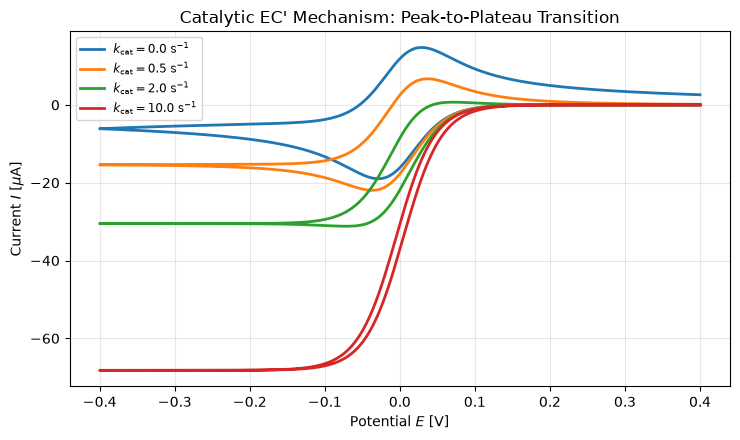

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for kcat, res in results.items():
    i_sim_min = res.current.min()
    if kcat > 0:
        i_cat_theory = -FARADAY * area * c_bulk * np.sqrt(D * kcat)
        print(f"k_cat = {kcat:4.1f} s^-1 | I_max(sim) = {i_sim_min*1e6:7.2f} uA | Theory I_cat = {i_cat_theory*1e6:7.2f} uA")
    else:
        print(f"k_cat = {kcat:4.1f} s^-1 | I_pc(sim)  = {i_sim_min*1e6:7.2f} uA (no catalysis)")
    ax.plot(res.potential, res.current * 1e6, lw=2, label=f"$k_{{\\mathrm{{cat}}}} = {kcat}$ s$^{{-1}}$")

ax.set_xlabel("Potential $E$ [V]")
ax.set_ylabel(r"Current $I$ [$\mu$A]")
ax.set_title("Catalytic EC' Mechanism: Peak-to-Plateau Transition")
ax.legend(fontsize=8.5)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Key Takeaways

- Regenerating $\text{Ox}$ in solution sustains a steady-state reaction–diffusion layer of thickness $\mu = \sqrt{D / k_{\text{cat}}}$.
- At large $k_{\text{cat}}$, the reverse peak disappears and the forward wave becomes a scan-rate-independent sigmoidal plateau with $I_{\text{cat}} = -n F A c^* \sqrt{D k_{\text{cat}}}$.
- **Next**: Read [Reaction Mechanisms Concepts](../../concepts/electrochemistry/mechanisms.md).